# Are MMA betting markets efficient at the extremes?

**Question.** When a UFC fight has a massive favorite and a massive underdog, do the betting
odds still reflect the true win probabilities — or does the market systematically misprice the tails?

This notebook tests the **favorite–longshot bias** (FLB), the best-documented anomaly in betting
markets (Griffith 1949; Snowberg & Wolfers 2010), on ~6,900 UFC fights from 2010–2026 with closing
moneyline odds.

**Findings in one paragraph.** The market is impressively well calibrated through the middle of the
probability range, and public fighter statistics add nothing beyond the closing line (a semi-strong
efficiency result). But the tails are bent, and in the classic FLB direction: heavy underdogs win far
less often than their price implies and heavy favorites win more. Flat-betting every +300-or-longer
underdog since 2010 lost **~29 cents per dollar** — ten times the bookmaker's margin — while
flat-betting every −300-or-shorter favorite roughly broke even *despite* the vig. The logistic
calibration slope on de-vigged probabilities is **1.11** (95% CI excludes 1), and the bias is, if
anything, strongest in the most recent era.

In [1]:
import sys, json
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else "src")

import numpy as np
import pandas as pd
from IPython.display import Image, display

from mma_efficiency import calibration, data, exploit, models, plots, returns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 160)

## 1. Data

The [Ultimate UFC Dataset](https://www.kaggle.com/datasets/mdabbert/ultimate-ufc-dataset)
(Apache-2.0, mirrored on [GitHub](https://github.com/shortlikeafox/ultimate_ufc_dataset)) pairs
every UFC bout since March 2010 with closing American moneyline odds and pre-fight career
statistics for both corners. We keep fights with two-sided odds and a plausible bookmaker margin.

Free, clean historical odds do not exist in public form for other MMA promotions
(Bellator / PFL / ONE), so the sample is UFC; every function in `src/` is promotion-agnostic and
will ingest any fight table with the same columns.

In [2]:
raw = data.load_raw(ROOT / "data" / "ufc-master.csv")   # downloads on first run
fights = data.build_fight_table(raw)
sides = data.side_table(fights)   # one row per *price* (two per fight), the bettor's unit

print(f"{len(fights):,} fights, {fights['date'].min():%b %Y} – {fights['date'].max():%b %Y}")
print(f"{int(fights['decisive'].sum()):,} decisive (draws/NC excluded: {int((~fights['decisive']).sum())})")
print(f"mean overround (booksum) = {fights['overround'].mean():.4f} "
      f"-> average vig ~ {fights['overround'].mean()-1:.1%}")
fights[["date","red","blue","r_odds","b_odds","r_p_raw","b_p_raw","r_p_basic","winner"]].head(5)

6,904 fights, Mar 2010 – Mar 2026
6,896 decisive (draws/NC excluded: 8)
mean overround (booksum) = 1.0355 -> average vig ~ 3.6%


,date,red,blue,r_odds,b_odds,r_p_raw,b_p_raw,r_p_basic,winner
0,2026-03-28,Israel Adesanya,Joe Pyfer,-130.0,102.0,0.565217,0.495050,0.533090,Blue
1,2026-03-28,Alexa Grasso,Maycee Barber,124.0,-158.0,0.446429,0.612403,0.421624,Red
2,2026-03-28,Michael Chiesa,Niko Price,-901.0,550.0,0.900100,0.153846,0.854028,Red
3,2026-03-28,Julian Erosa,Lerryan Douglas,235.0,-320.0,0.298507,0.761905,0.281501,Blue
4,2026-03-28,Mansur Abdul-Malik,Yousri Belgaroui,-158.0,124.0,0.612403,0.446429,0.578376,Blue


## 2. From prices to probabilities

American odds convert to a *raw* implied probability (the break-even probability). The two sides of
a fight sum to more than 1 — the excess (~4.8% here) is the bookmaker's margin ("vig"). To ask
whether *probabilities* are mispriced we remove the vig two ways:

* **Proportional (basic):** divide by the booksum — the standard baseline.
* **Shin (1993):** a structural model in which the bookmaker defends against insiders and shades
  longshots the most. Since Shin's correction *itself* moves probability toward favorites, any bias
  that survives it is a conservative finding.

Every statistical test below clusters by fight (the two sides of one fight are mirror images, never
independent observations).

## 3. Calibration: implied probability vs. what actually happened

If prices are efficient, fighters priced at 20% win 20% of the time. We bucket every side by its
de-vigged implied probability and compare with the realized win rate (95% Wilson intervals).

In [3]:
cal_tab = calibration.bucket_binomial_tests(sides, "p_basic")
cal_tab.round(4)

,bucket,n,wins,implied,implied_raw,mean_odds,actual,actual_lo,actual_hi,gap,binom_p,binom_p_bh
0,"[0.0, 0.1)",20,0,0.0881,0.0908,1011.7500,0.0000,0.0000,0.1611,-0.0881,0.2516,0.3145
1,"[0.1, 0.2)",601,77,0.1633,0.1690,508.7604,0.1281,0.1037,0.1572,-0.0352,0.0203,0.0507
2,"[0.2, 0.3)",1616,355,0.2543,0.2629,285.3979,0.2197,0.2002,0.2405,-0.0346,0.0012,0.0094
3,"[0.3, 0.4)",2341,830,0.3506,0.3627,177.4169,0.3545,0.3354,0.3742,0.0040,0.6967,0.6967
4,"[0.4, 0.5)",2198,1003,0.4434,0.4599,98.3549,0.4563,0.4356,0.4772,0.0130,0.2212,0.3145
5,"[0.5, 0.6)",2318,1255,0.5537,0.5743,-136.0440,0.5414,0.5211,0.5616,-0.0123,0.2338,0.3145
6,"[0.6, 0.7)",2341,1511,0.6494,0.6720,-207.6783,0.6455,0.6258,0.6646,-0.0040,0.6967,0.6967
7,"[0.7, 0.8)",1622,1264,0.7459,0.7711,-345.2195,0.7793,0.7585,0.7988,0.0334,0.0019,0.0094
8,"[0.8, 0.9)",595,521,0.8371,0.8668,-695.2118,0.8756,0.8467,0.8998,0.0385,0.0105,0.0352
9,"[0.9, 1.0)",20,20,0.9119,0.9400,-1613.7500,1.0000,0.8389,1.0000,0.0881,0.2516,0.3145


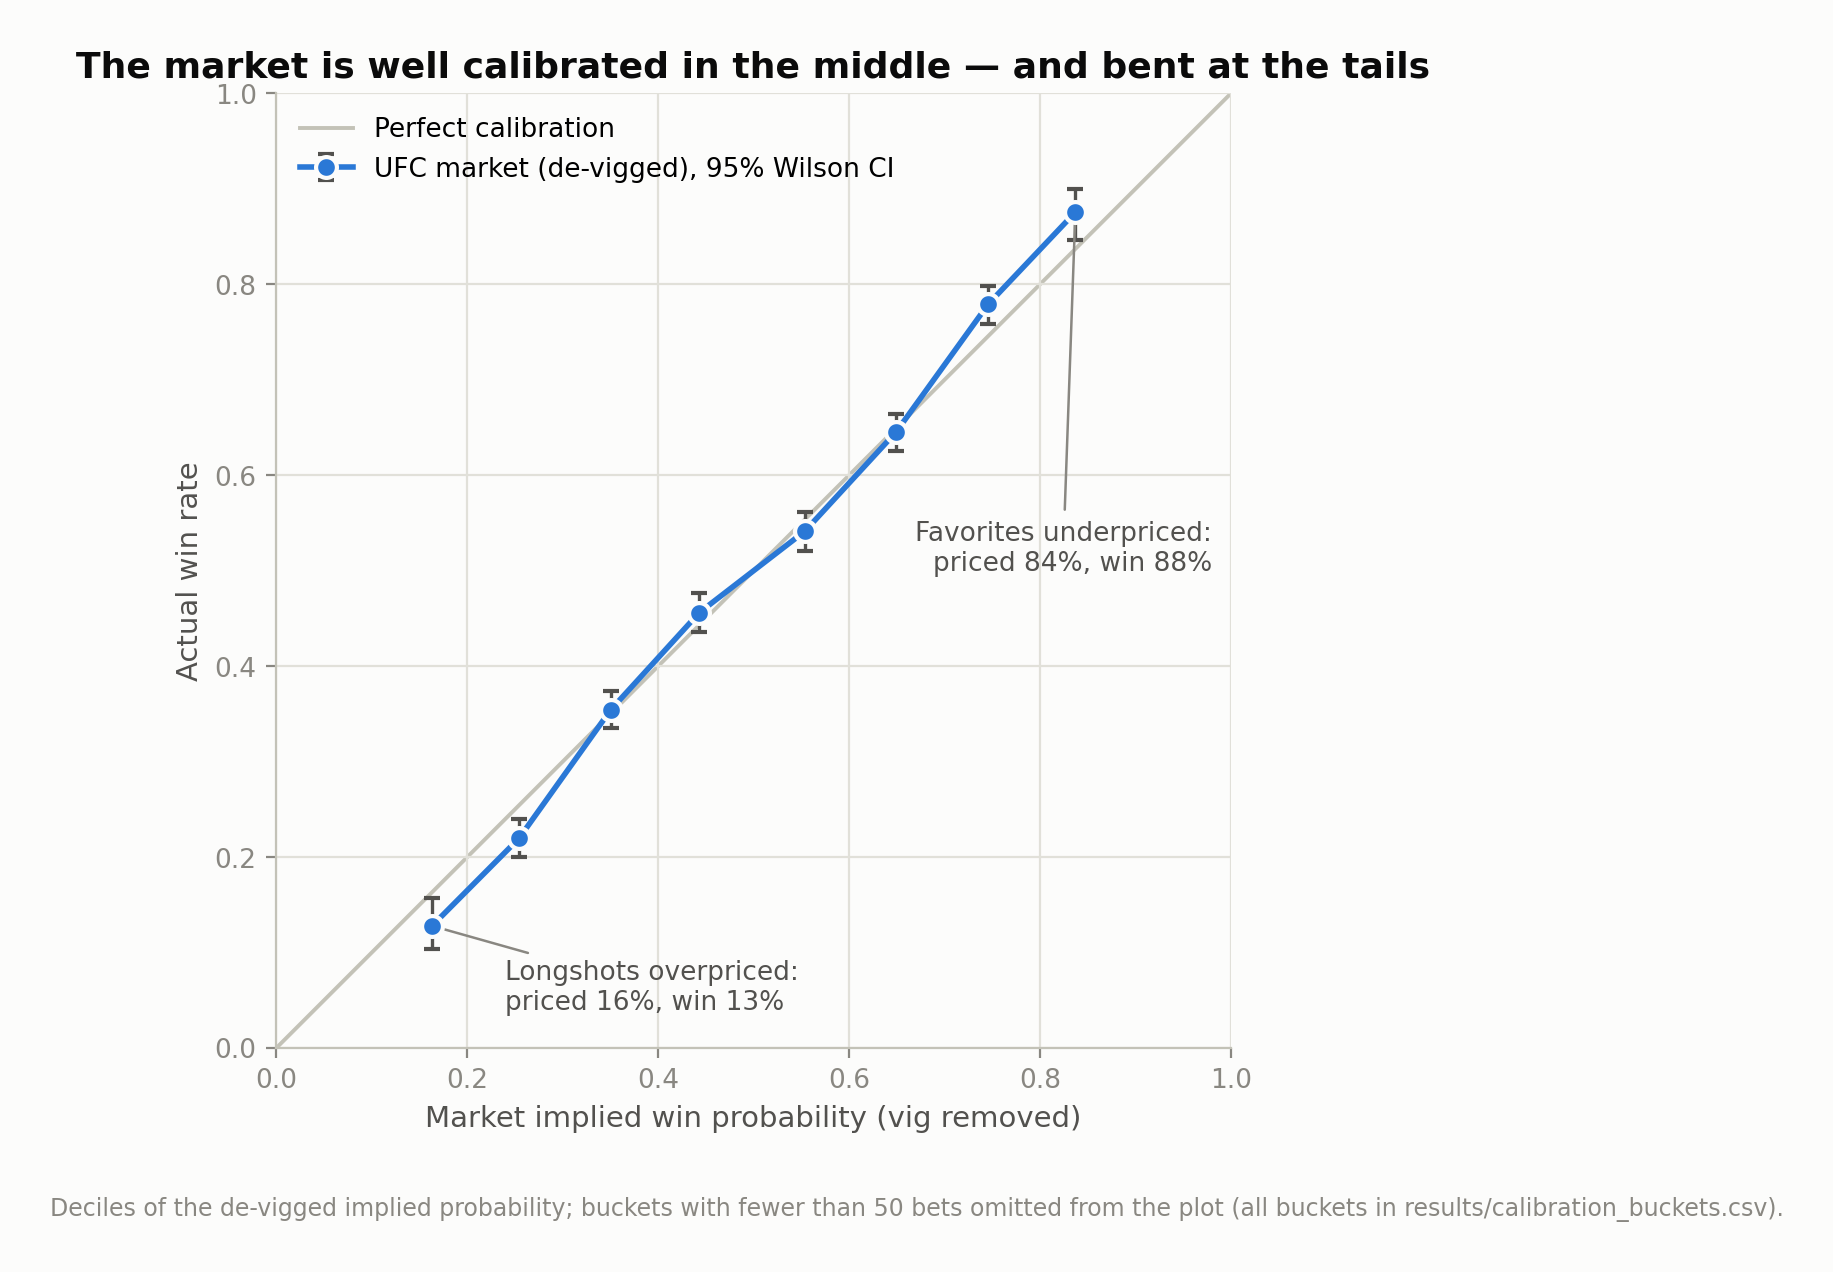

In [4]:
plots.plot_calibration(cal_tab, FIG / "calibration.png")
Image(filename=str(FIG / "calibration.png"), width=760)

### Robustness: equal-count bins

Fixed-width deciles put very different numbers of bets in each bucket. As a check that the tails are
not a binning artifact, we re-bin into **quantile buckets** — every point is ~500 bets grouped by
nearest market price, so each carries the same statistical power.

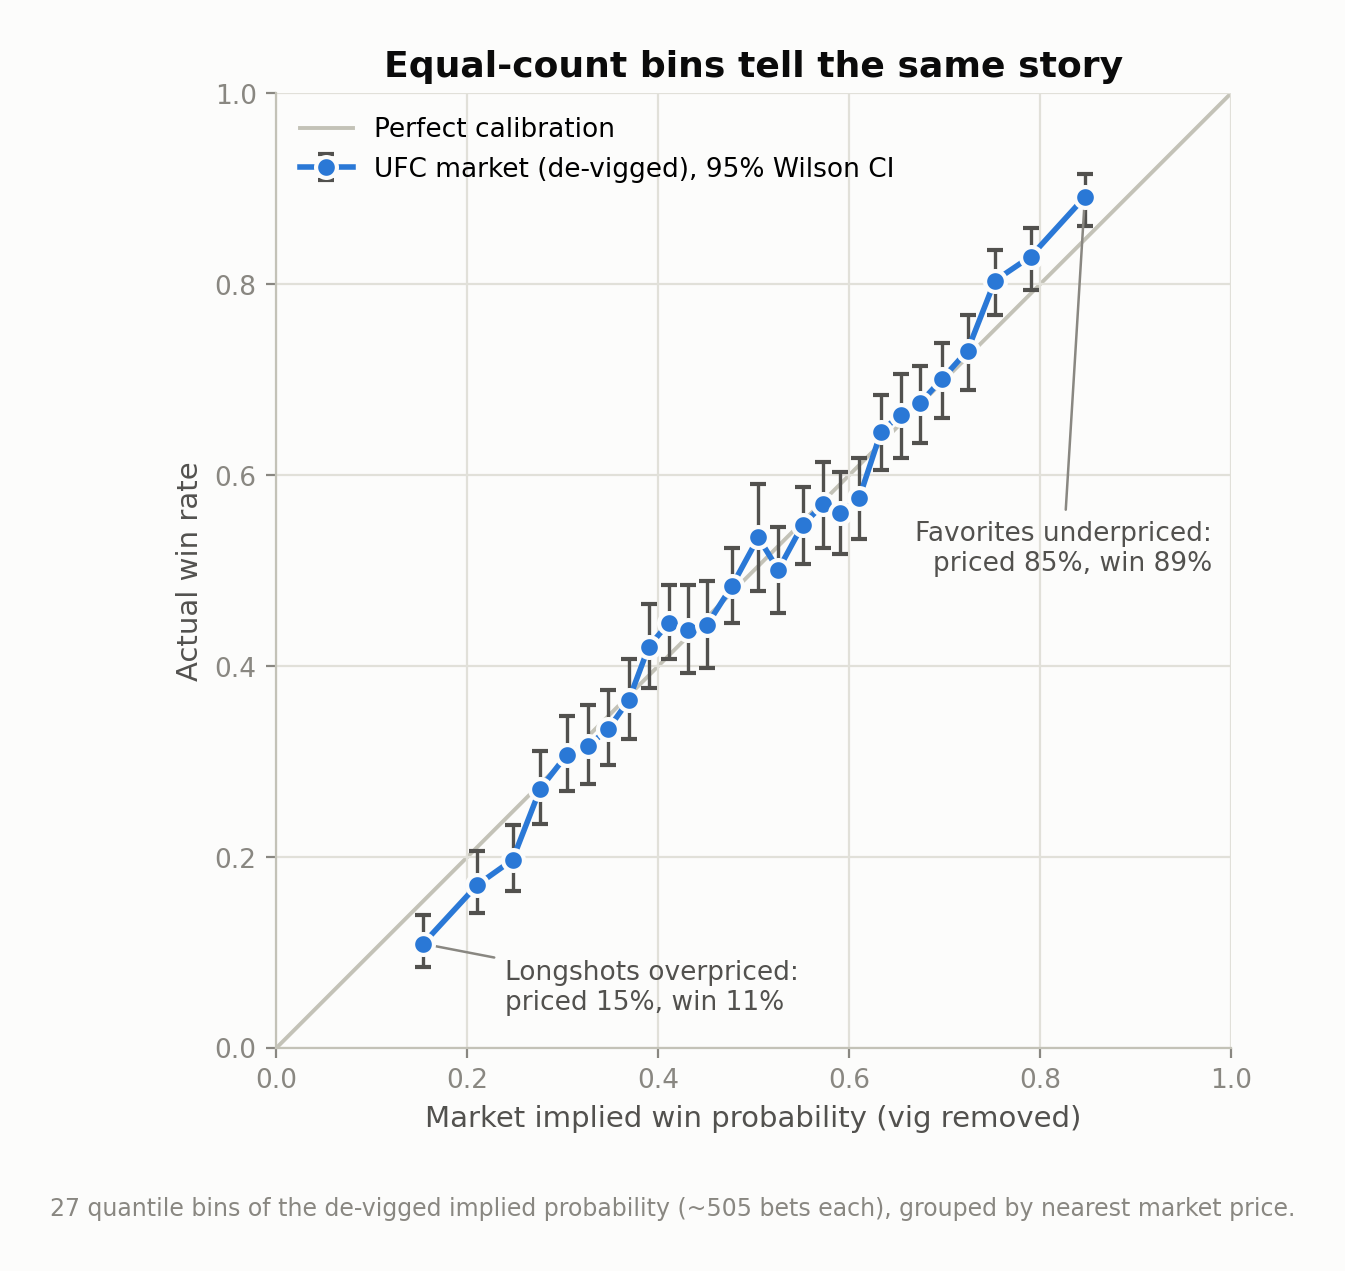

In [5]:
n_eq = max(10, len(sides) // 500)
cal_eq = calibration.bucket_binomial_tests(sides, "p_basic", equal_count=n_eq)
plots.plot_calibration(
    cal_eq, FIG / "calibration_equal_count.png",
    title="Equal-count bins tell the same story",
    caption=f"{len(cal_eq)} quantile bins of the de-vigged implied probability "
            f"(~{int(cal_eq['n'].mean())} bets each), grouped by nearest market price.")
Image(filename=str(FIG / "calibration_equal_count.png"), width=760)

Same picture: below the diagonal through the longshot range, above it across the favorite range.
(Technical note: when both sides of a near-pick'em fight fall in one bucket, we keep one side,
alternating deterministically — always keeping the red corner would paint a spurious kink at 0.5,
because red corners actually win **62.5%** of the 120 exact pick'em fights in the sample. That
corner-assignment effect is itself a fun candidate mispricing, but n = 120, so we flag it rather
than claim it.)

The pattern is the favorite–longshot bias exactly as the literature describes it: the curve sits
**below** the diagonal on the left (longshots overpriced) and **above** it on the right (favorites
underpriced), while the middle deciles are almost perfectly calibrated. The per-bucket exact binomial
tests (Benjamini–Hochberg corrected, table above) reject calibration in the tail buckets specifically.

### Formal test

We fit a Mincer–Zarnowitz-style logistic recalibration,
$P(\text{win}) = \sigma\big(a + b\,\text{logit}(\hat p)\big)$, with fight-clustered standard
errors. Perfect calibration means $b = 1$; $b > 1$ means outcomes are more extreme than prices —
the FLB signature. (With de-vigged probabilities the mirrored design forces $a = 0$, so the slope
carries the whole test.)

In [6]:
tests = pd.DataFrame([
    calibration.logistic_calibration_test(sides, pc)
    for pc in ("p_raw", "p_basic", "p_shin")
])
tests[["prob_col","n_fights","slope","slope_se","slope_z_vs_1","slope_p_vs_1"]].round(4)

/usr/local/lib/python3.11/dist-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 2, but rank is 1
  warnings.warn('covariance of constraints does not have full '
/usr/local/lib/python3.11/dist-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 2, but rank is 1
  warnings.warn('covariance of constraints does not have full '


,prob_col,n_fights,slope,slope_se,slope_z_vs_1,slope_p_vs_1
0,p_raw,6896,1.0635,0.0338,1.8751,0.0608
1,p_basic,6896,1.1142,0.0353,3.2324,0.0012
2,p_shin,6896,1.0677,0.0339,1.9943,0.0461


The slope is significantly above 1 for raw and proportionally de-vigged probabilities, and remains
above 1 (p < 0.05) even under Shin's insider-trading correction — the bias is not an artifact of how
the margin is removed.

## 4. The economic version: what a bettor would have earned

Calibration gaps only matter if they are big enough to survive the vig. Under an efficient market
with a proportional margin, a flat 1-unit bet on *any* price has the same expected return:
$1/r - 1 \approx -3.4\%$. So mean returns by odds band are a sharp test: efficiency predicts a
flat profile at the gray line; FLB predicts returns that fall as odds get longer.

In [7]:
band_tab = returns.returns_by_band(sides)
band_tab.round(4)

,band,n_bets,mean_odds,implied_raw,implied_devig,win_rate,mean_return,ci_lo,ci_hi,vig_null_return,p_vs_vig_null
0,-800 or shorter,175,-1065.8171,0.9104,0.8768,0.9086,-0.0025,-0.0515,0.0425,-0.0369,0.1365
1,-799 to -500,408,-600.8652,0.8555,0.8257,0.8799,0.0284,-0.0081,0.0647,-0.0348,0.0015
2,-499 to -300,1221,-372.2948,0.7855,0.7593,0.7952,0.0124,-0.0157,0.0420,-0.0333,0.0015
3,-299 to -200,1806,-239.7663,0.7038,0.6795,0.6860,-0.0249,-0.0554,0.0055,-0.0346,0.5325
4,-199 to -140,2050,-163.9039,0.6196,0.5999,0.5854,-0.0555,-0.0892,-0.0226,-0.0319,0.1755
5,-139 to +99,1576,-119.5774,0.5435,0.5223,0.5114,-0.0594,-0.0926,-0.0263,-0.0392,0.2425
6,+100 to +139,1746,118.3173,0.4593,0.4428,0.4576,-0.0040,-0.0551,0.0461,-0.0357,0.2225
7,+140 to +199,2054,165.3442,0.3784,0.3662,0.3700,-0.0246,-0.0808,0.0324,-0.0325,0.7635
8,+200 to +299,1537,239.8113,0.2963,0.2864,0.2811,-0.0542,-0.1300,0.0240,-0.0331,0.6050
9,+300 to +499,937,370.3511,0.2152,0.2082,0.1558,-0.2678,-0.3741,-0.1531,-0.0323,0.0000


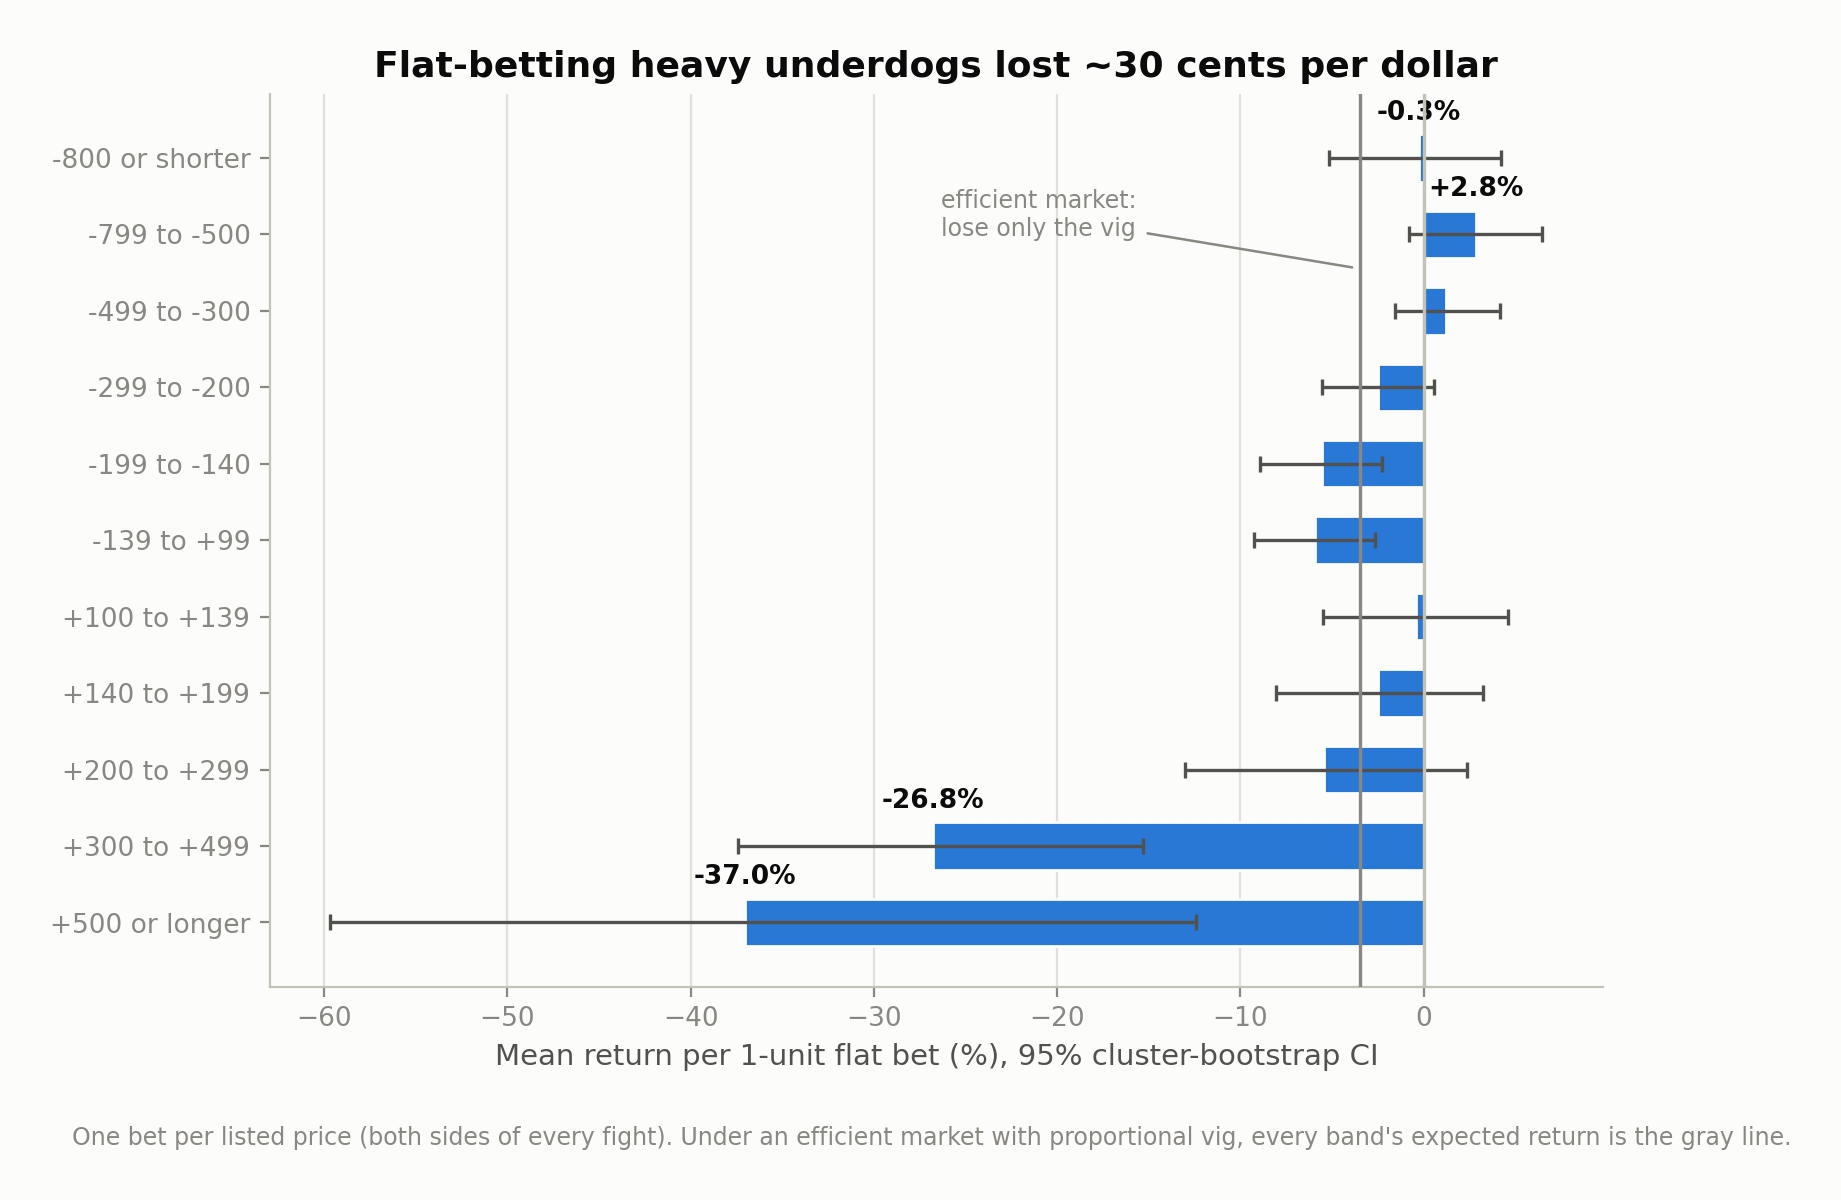

In [8]:
plots.plot_returns_by_band(band_tab, FIG / "returns_by_band.png")
Image(filename=str(FIG / "returns_by_band.png"), width=860)

In [9]:
trend = returns.returns_trend_test(sides)
print(f"OLS: flat-bet return on implied probability -> slope {trend['slope']:+.3f} "
      f"(t = {trend['t_stat']:.2f}, p = {trend['p_value']:.2g})")
print("Positive slope = the shorter the price, the better the bet: the FLB in return space.")

OLS: flat-bet return on implied probability -> slope +0.258 (t = 3.76, p = 0.00017)
Positive slope = the shorter the price, the better the bet: the FLB in return space.


Heavy underdogs are catastrophic bets: **−26.8%** per unit at +300 to +499 and **−37.0%** at +500 or
longer, both far below the vig-only benchmark (bootstrap p < 0.001). Heavy favorites, meanwhile,
returned around **zero to +2.8%** — significantly *better* than the benchmark, i.e. the vig didn't
even cover the underpricing. A simple ~4.8% margin cannot explain a 30-point loss; that is
probability mispricing.

In [10]:
bt = returns.backtest_rules(sides)
bt.round(4)

,strategy,n_bets,total_staked,total_profit,roi,roi_ci_lo,roi_ci_hi,win_rate,max_drawdown
0,All favorites,6776,6776.0,-196.5806,-0.0290,-0.0453,-0.0121,0.6657,-222.7970
1,All underdogs,6776,6776.0,-515.4074,-0.0761,-0.1088,-0.0435,0.3343,-534.6999
2,Heavy favorites (-300 or shorter),1804,1804.0,26.2637,0.0146,-0.0069,0.0357,0.8254,-14.1542
3,Moderate favorites (-299 to -105),5432,5432.0,-252.4280,-0.0465,-0.0650,-0.0277,0.5974,-266.4134
4,Moderate underdogs (+100 to +299),5337,5337.0,-140.8200,-0.0264,-0.0604,0.0089,0.3731,-196.1300
5,Heavy underdogs (+300 or longer),1219,1219.0,-355.3200,-0.2915,-0.3903,-0.1892,0.1403,-357.0200
6,Extreme underdogs (+500 or longer),282,282.0,-104.4000,-0.3702,-0.5910,-0.1161,0.0887,-110.6000


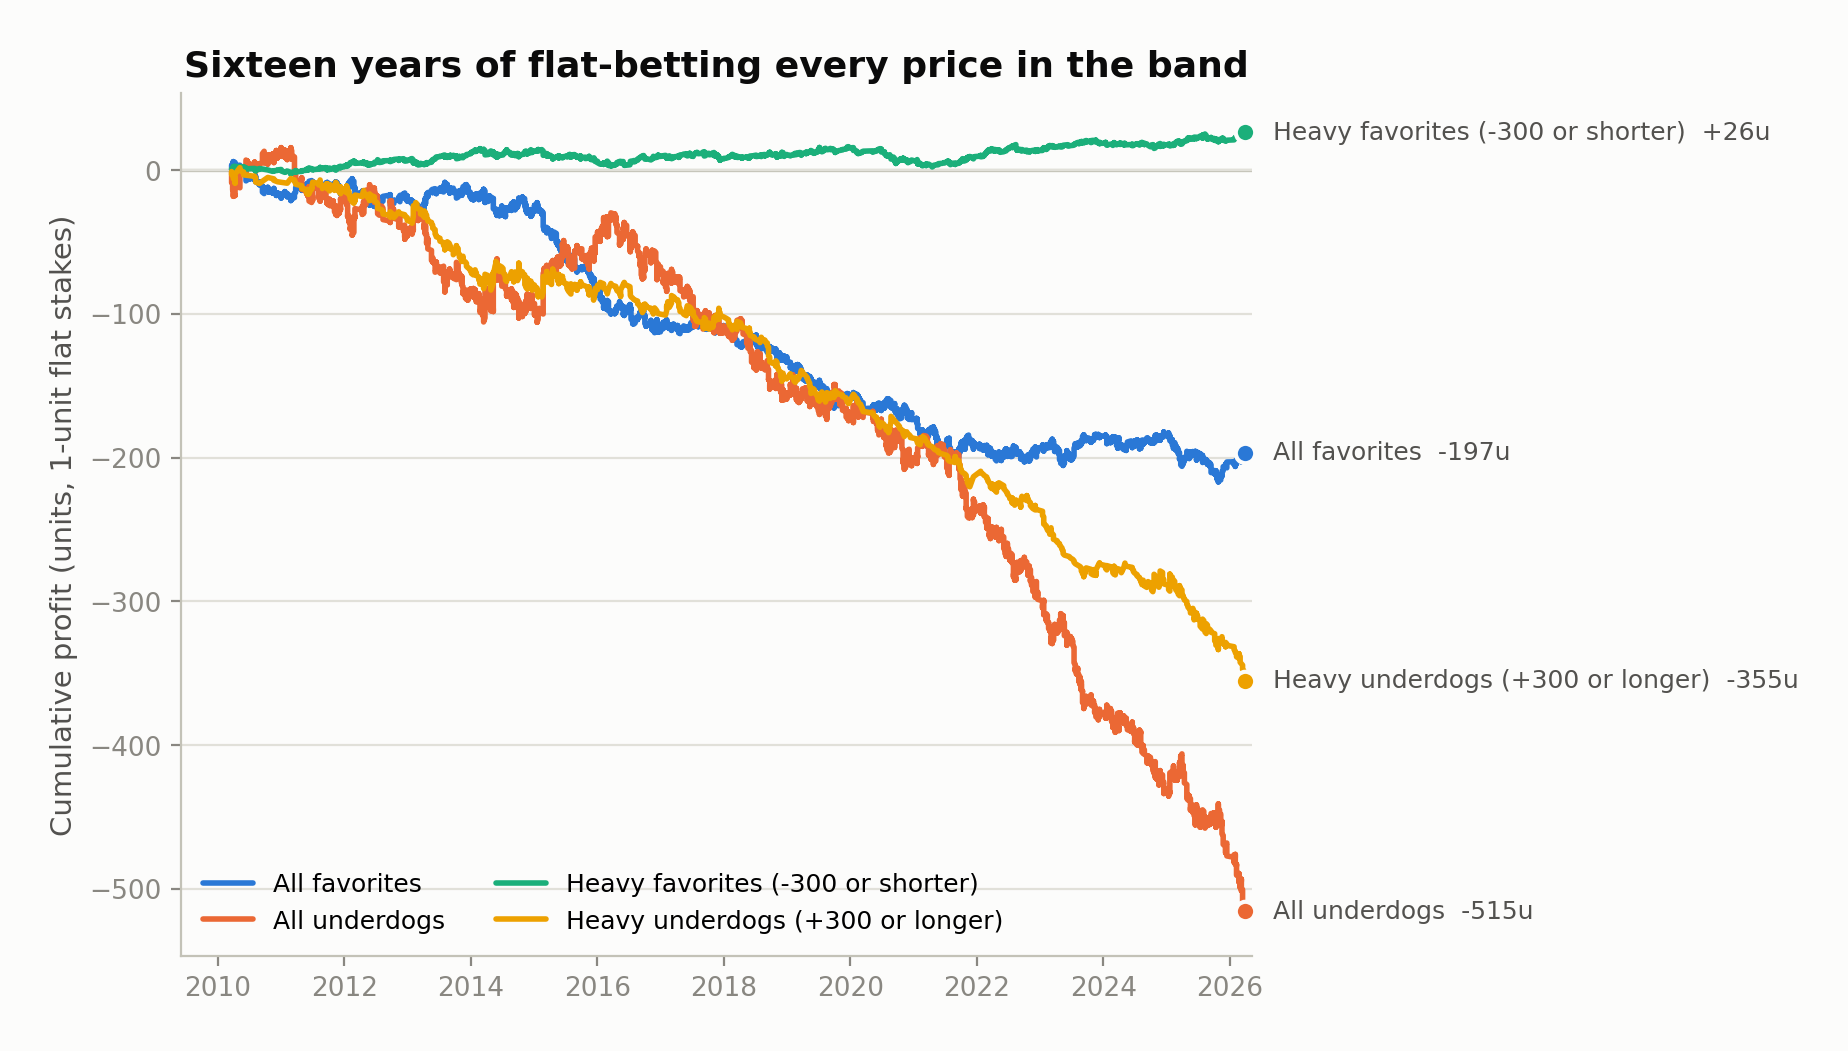

In [11]:
pnl = returns.cumulative_pnl(sides, {
    "All favorites": sides["is_favorite"],
    "All underdogs": sides["is_underdog"],
    "Heavy favorites (-300 or shorter)": sides["odds"] <= -300,
    "Heavy underdogs (+300 or longer)": sides["odds"] >= 300,
})
plots.plot_cumulative_pnl(pnl, FIG / "cumulative_pnl.png")
Image(filename=str(FIG / "cumulative_pnl.png"), width=900)

Sixteen years of flat stakes: betting every heavy favorite ends **positive (+26 units on 1,804
bets)** while betting every heavy underdog loses 355 units on 1,219 bets. These are historical
closing-line diagnostics (no limits, fees, or line movement), **not** betting advice — but as a test
statistic the separation is unambiguous.

## 5. Is the bias a relic of the early UFC market?

A common story is that early MMA books were soft and the market has since sharpened. Re-running the
calibration test by era says otherwise.

/usr/local/lib/python3.11/dist-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 2, but rank is 1
  warnings.warn('covariance of constraints does not have full '
/usr/local/lib/python3.11/dist-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 2, but rank is 1
  warnings.warn('covariance of constraints does not have full '
/usr/local/lib/python3.11/dist-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 2, but rank is 1
  warnings.warn('covariance of constraints does not have full '
/usr/local/lib/python3.11/dist-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 2, but rank is 1
  warnings.warn('covariance of constraints does not have full '


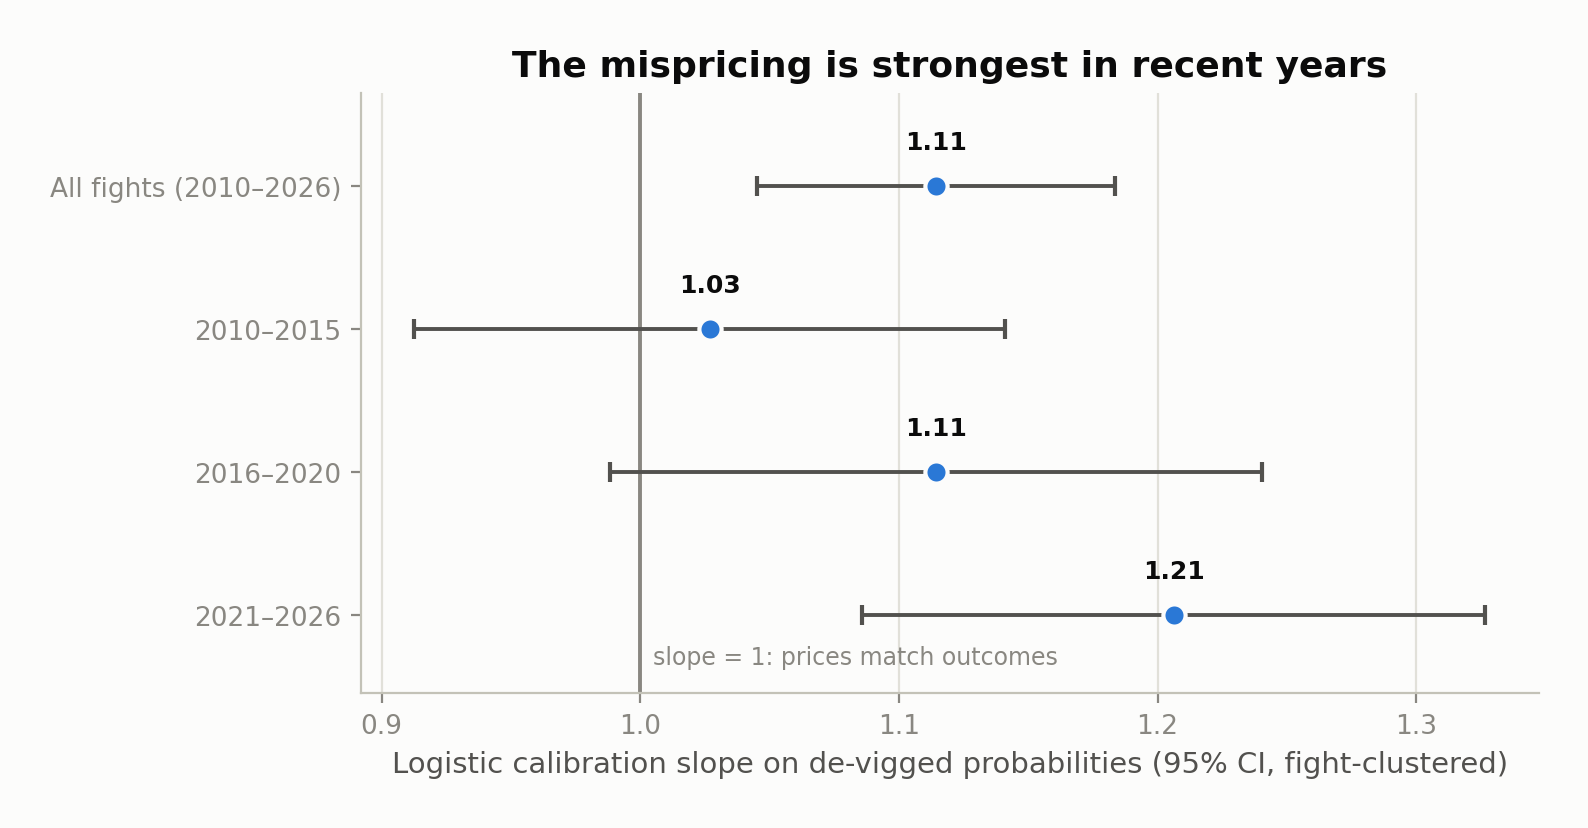

In [12]:
ERAS = [("2010–2015","2010-01-01","2016-01-01"),
        ("2016–2020","2016-01-01","2021-01-01"),
        ("2021–2026","2021-01-01","2027-01-01")]
era_rows = [dict(label="All fights (2010–2026)",
                 **calibration.logistic_calibration_test(sides, "p_basic"))]
for label, s, e in ERAS:
    m = (sides["date"] >= pd.Timestamp(s)) & (sides["date"] < pd.Timestamp(e))
    era_rows.append(dict(label=label, **calibration.logistic_calibration_test(sides[m], "p_basic")))

plots.plot_slope_stability(
    [{k: r[k] for k in ("label","slope","slope_se")} for r in era_rows],
    FIG / "slope_stability.png")
Image(filename=str(FIG / "slope_stability.png"), width=780)

The point estimate *rises* across eras (1.03 → 1.11 → 1.21); the recent era rejects efficiency on
its own. Whatever drives the bias — recreational money chasing upsets and parlays, books shading
prices accordingly, limits on sharp play — it has not been arbitraged away.

## 6. Semi-strong efficiency: can public information beat the line?

Mispriced tails are one thing; a *predictably beatable* market is a stronger claim. We test whether
public pre-fight information — career records, physical stats, streaks, striking/grappling averages,
oriented favorite-minus-underdog — improves on the market's own probability out of sample
(chronological split: fit ≤ 2021, evaluate 2022–2026, paired bootstrap on test log-loss).

In [13]:
model_table = models.build_model_table(raw, fights)
ml_res, ml_extra = models.run_benchmark(model_table, split_date="2022-01-01")
ml_res.round(4)

,model,n_test,log_loss,brier,auc,logloss_diff,diff_ci_lo,diff_ci_hi,p_model_better
0,Market (de-vigged odds),1882,0.5878,0.2013,0.6415,NaN,NaN,NaN,NaN
1,Stats only (logistic),1882,0.6056,0.2081,0.5831,0.0178,0.0090,0.0266,1.0000
2,Stats + market (logistic),1882,0.5851,0.2006,0.6454,-0.0027,-0.0075,0.0021,0.1380
3,Stats + market (grad. boosting),1882,0.5986,0.2066,0.6324,0.0107,0.0007,0.0209,0.9822


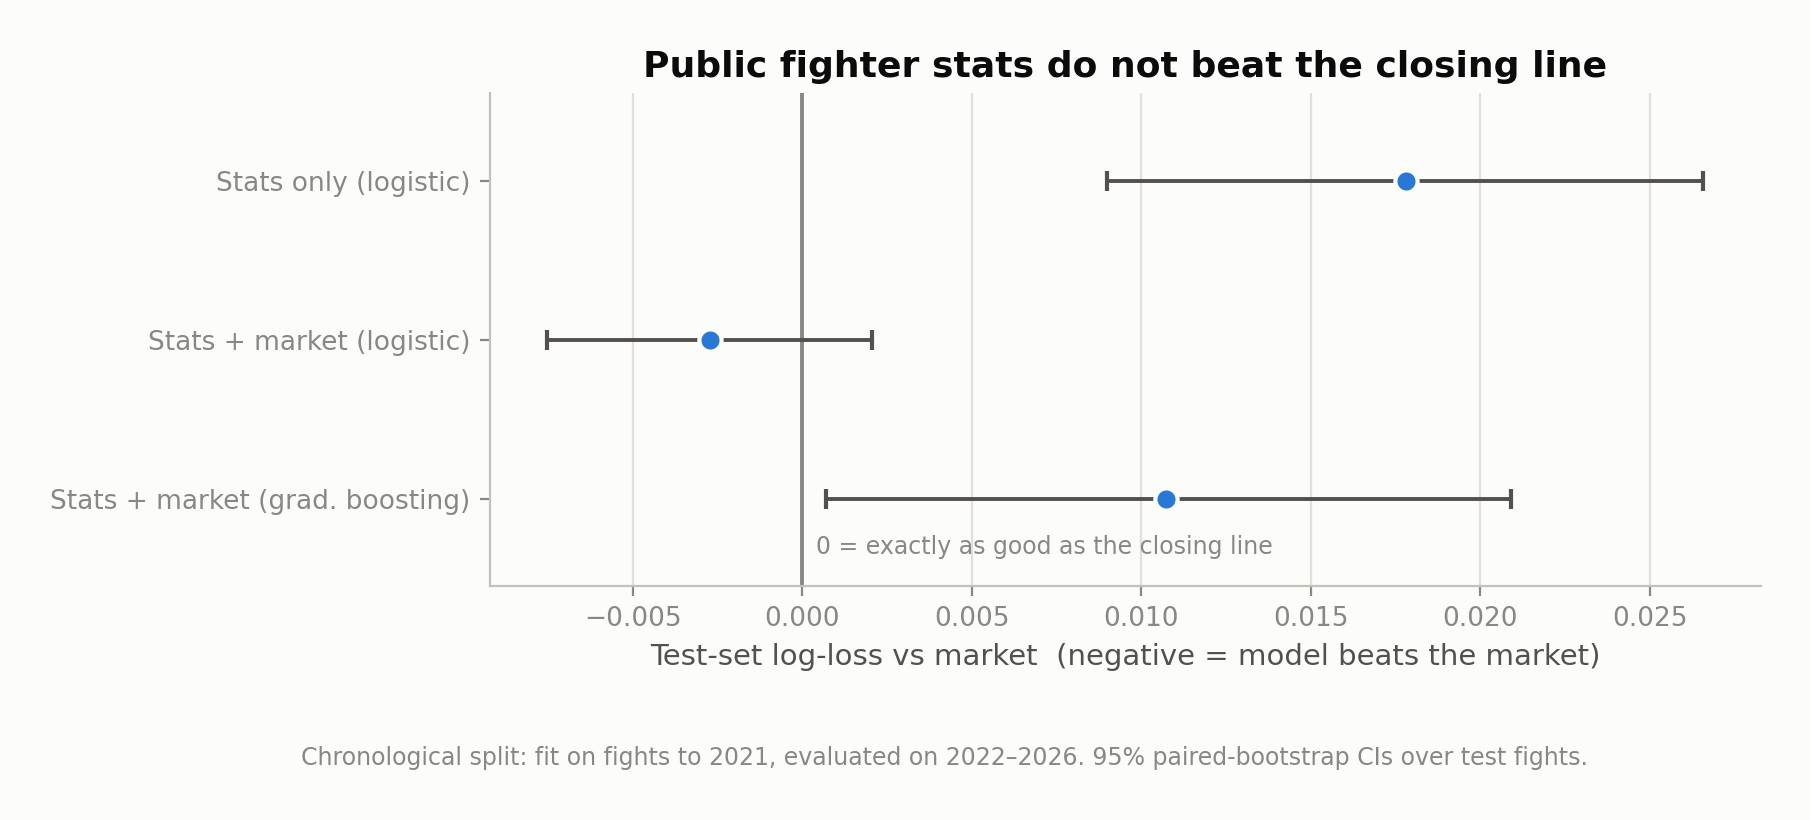

In [14]:
plots.plot_ml_benchmark(ml_res, FIG / "ml_benchmark.png")
Image(filename=str(FIG / "ml_benchmark.png"), width=840)

In [15]:
edge = models.edge_backtest(ml_extra["test"], ml_extra["preds"]["Stats + market (logistic)"])
edge.round(4)

,min_edge,n_bets,share_underdog_bets,roi,roi_ci_lo,roi_ci_hi,p_roi_gt0,total_profit
0,0.00,1220,0.4557,-0.0081,-0.0618,0.0466,0.6202,-9.8886
1,0.02,911,0.5302,0.0052,-0.0600,0.0715,0.4312,4.7735
2,0.05,565,0.6531,0.0024,-0.0845,0.0944,0.4675,1.3555
3,0.10,251,0.8167,0.0182,-0.1221,0.1608,0.3980,4.5798


Stats alone are *much* worse than the market; adding stats to the market probability improves
log-loss by a statistically indistinguishable −0.003; gradient boosting overfits and loses. Betting
where the model disagrees with the price does not produce reliable profit. **The closing line
already impounds public fighter statistics.**

## 7. Is the bias exploitable?

A biased price and an exploitable price are different claims. To profit, a bettor must (a) overcome
the vig and (b) commit to a rule *before* seeing how it performs — scanning 16 years for the
best-looking cell and reporting its return is data snooping. The walk-forward test below selects a
favorite-cutoff rule on 2010–2017 only, using the most pessimistic criterion (highest bootstrap
lower confidence bound), then stakes it blind on 2018–2026.

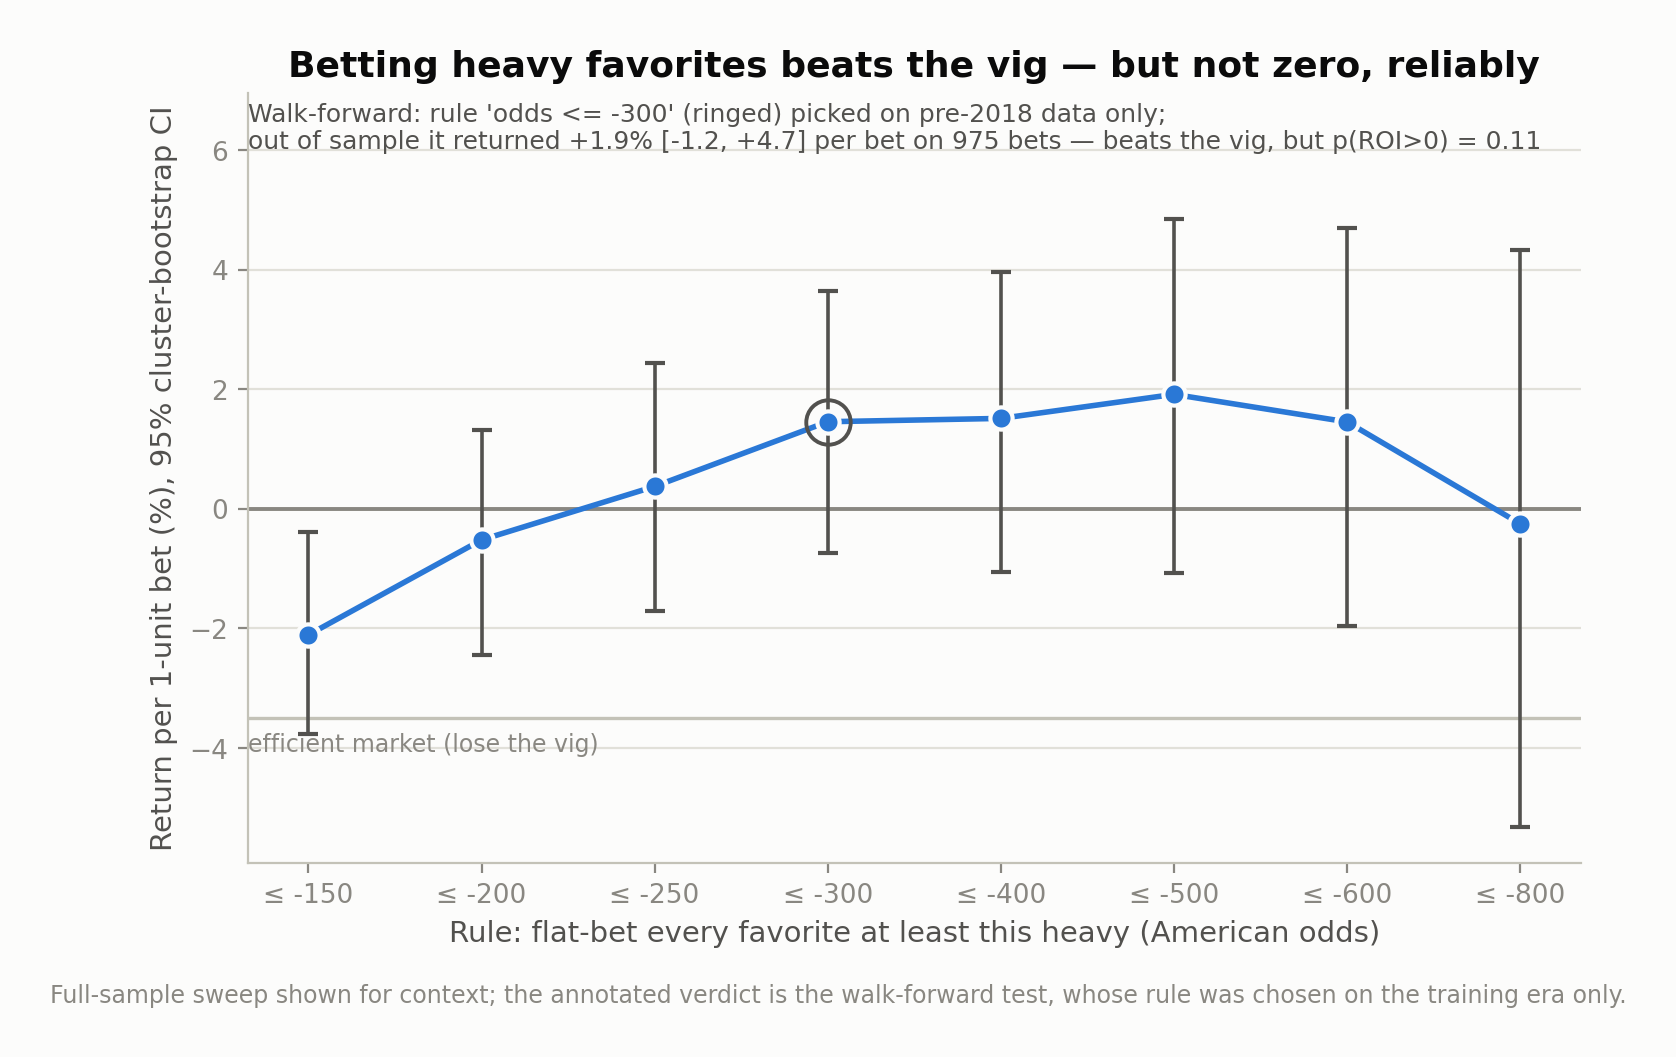

In [16]:
sweep_fav = exploit.threshold_sweep(sides)
wf = exploit.walk_forward_rule(sides)   # rule chosen on pre-2018 data only
plots.plot_threshold_sweep(sweep_fav, wf, FIG / "exploitability.png")
Image(filename=str(FIG / "exploitability.png"), width=860)

In [17]:
print(f"chosen on 2010–2017: '{wf['chosen_rule']}' "
      f"(train ROI {wf['train_roi']:+.2%} on {wf['train_n_bets']:,} bets)")
print(f"out-of-sample 2018–2026: ROI {wf['test_roi']:+.2%} on {wf['test_n_bets']:,} bets "
      f"(total {wf['test_total_profit']:+.1f} units)")
print(f"95% CI [{wf['test_roi_ci'][0]:+.2%}, {wf['test_roi_ci'][1]:+.2%}], "
      f"one-sided p(ROI>0) = {wf['test_p_roi_gt0']:.3f}; "
      f"efficient-market benchmark {wf['test_vig_null']:+.2%}")

chosen on 2010–2017: 'odds <= -300' (train ROI +0.98% on 829 bets)
out-of-sample 2018–2026: ROI +1.86% on 975 bets (total +18.1 units)
95% CI [-1.18%, +4.68%], one-sided p(ROI>0) = 0.106; efficient-market benchmark -4.00%


### What changes on a prediction market? Kalshi's fees, exactly

The +1.9% above is measured at sportsbook closing prices, where the friction — the ~3.5-point
overround — is *inside* the price. Event-contract exchanges price the same event differently: a
YES contract on the favorite trades at some price $P \in (0,1)$ and pays \$1, with no vig in the
price; the frictions are an explicit **trading fee** and the **bid–ask spread**. Kalshi's official
fee schedule (kalshi.com/docs/kalshi-fee-schedule.pdf, effective 2026-07-07) charges, per contract
and only on execution (settlement is free):

$$\text{taker: } 0.07\,P(1-P) \qquad \text{maker: } 0.0175\,P(1-P)$$

The fee is a parabola peaking at $P=0.50$ (1.75¢) — and this study's edge lives at $P≈0.75$–$0.90$,
where the taker fee is only 0.6–1.3¢ per contract, i.e. **0.7–1.5% of stake** (as a share of stake
it is exactly $0.07(1-P)$, *falling* in the favorite's price). Compare ~4% lost to the vig at a book.

No exchange listed UFC fights before 2025, so historical Kalshi prices for this sample do not
exist. Execution there is therefore modeled under explicit counterfactual price assumptions, from
optimistic (the exchange mid tracks the de-vigged book consensus — the standard assumption for
liquid sports markets) through a 1–2¢ half-spread, to the worst case (the exchange price embeds
the book's full margin). Buying $1/(P+\text{fee})$ contracts per \$1 staked reproduces the
sportsbook flat-bet return exactly under (price = raw close, fee = 0), which is unit-tested —
the scenarios generalize the baseline, they don't change the accounting.

,label,mean_price,mean_fee_pct_of_stake,roi,ci_lo,ci_hi,p_roi_gt0
0,"Sportsbook, closing line (baseline)",0.8159,0.0000,0.0186,-0.0119,0.0466,0.0978
1,Kalshi taker at de-vigged mid,0.7832,0.0149,0.0452,0.0138,0.0739,0.0005
2,"Kalshi taker, mid + 1c half-spread",0.7932,0.0143,0.0327,0.0016,0.0610,0.0118
3,"Kalshi taker, mid + 2c half-spread",0.8032,0.0136,0.0205,-0.0102,0.0485,0.0755
4,Kalshi maker at de-vigged mid,0.7832,0.0038,0.0570,0.0253,0.0860,0.0000
5,Kalshi taker at book price (worst case),0.8159,0.0127,0.0057,-0.0244,0.0332,0.3520


win rate 83.2% vs de-vigged mid 78.3% -> edge at the mid +4.9 points of probability
breakeven total friction: 6.2% of the mid; the Kalshi taker fee uses 1.5%, leaving ~3.7 cents/contract of headroom for the spread


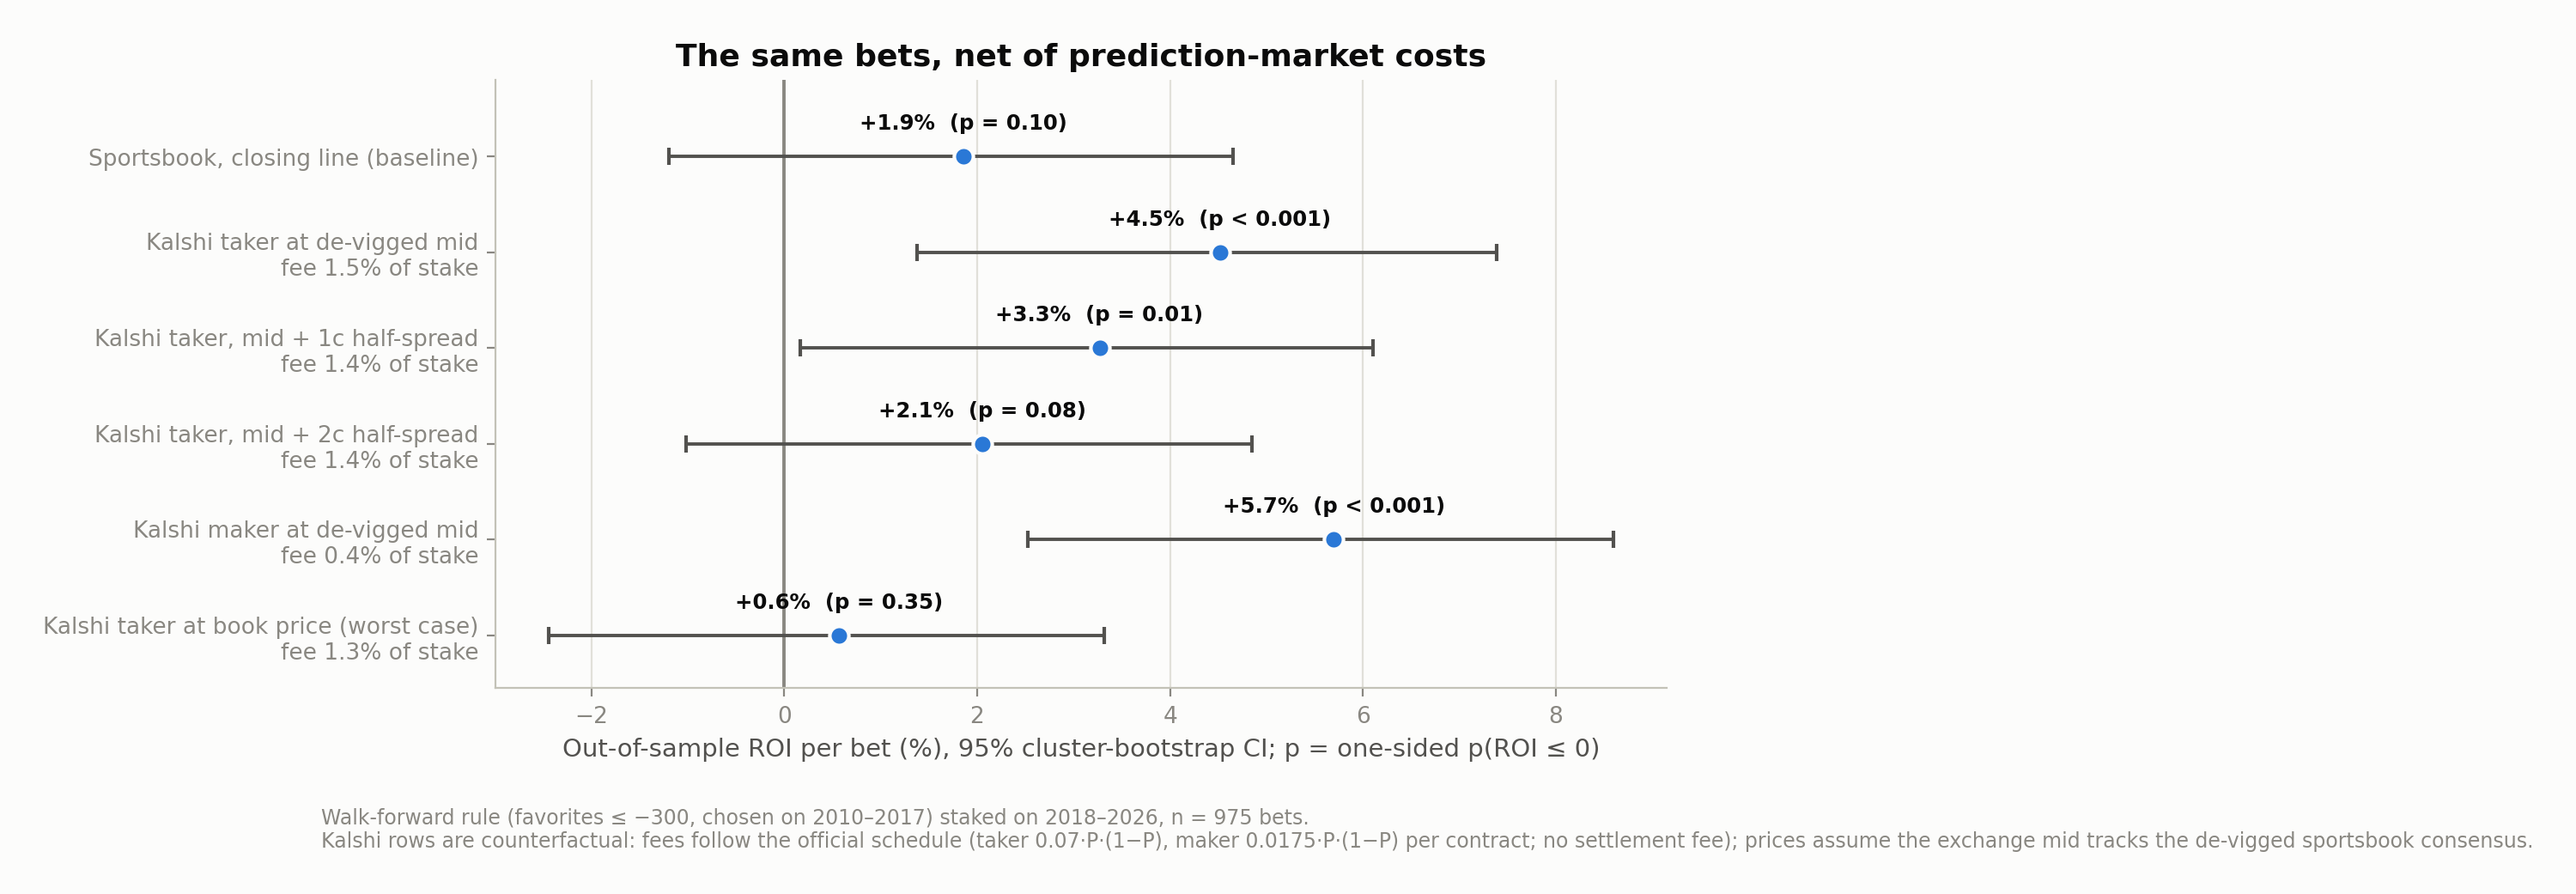

In [18]:
from mma_efficiency import costs

split = pd.Timestamp(wf["train_end"])
wf_bets = sides[(sides["date"] >= split) & (sides["odds"] <= wf["chosen_cutoff"])]
fee_tab = costs.fee_scenario_table(wf_bets, seed=17)
plots.plot_fee_scenarios(fee_tab, FIG / "fees_scenarios.png")

cols = ["label", "mean_price", "mean_fee_pct_of_stake", "roi", "ci_lo", "ci_hi", "p_roi_gt0"]
display(fee_tab[cols].round(4))

b = costs.breakeven_friction(wf_bets)
print(f"win rate {b['win_rate']:.1%} vs de-vigged mid {b['mean_mid']:.1%} "
      f"-> edge at the mid {b['edge_vs_mid']*100:+.1f} points of probability")
print(f"breakeven total friction: {b['breakeven_total_friction_pct_of_mid']:.1%} of the mid; "
      f"the Kalshi taker fee uses {b['kalshi_taker_fee_at_mid_pct']:.1%}, leaving "
      f"~{b['residual_for_spread_cents']:.1f} cents/contract of headroom for the spread")
Image(filename=str(FIG / "fees_scenarios.png"), width=880)

Fees are **not** the binding constraint — they are an order of magnitude smaller than the
mispricing at heavy-favorite prices. If the exchange mid tracks the de-vigged consensus, the
pre-registered rule's out-of-sample profit clears zero decisively (**+4.5% per bet, p < 0.001**,
still +3.3%, p = 0.01 through a 1¢ half-spread), because the ~4 points the book kept as vig go to
the bettor instead. The verdict flips only through *price formation*: at a 2¢ half-spread the edge
thins to +2.1% (p = 0.08), and if the exchange trades at book-equivalent prices the edge is gone
(+0.6%, p = 0.35). What this dataset cannot tell us is which scenario real Kalshi UFC markets
resemble — that requires collecting exchange quotes going forward.

The verdict is two-sided and worth stating carefully. The pre-registered rule **made money out of
sample** (+1.9% per bet, +18 units) and beat the efficient-market benchmark by ~6 percentage points —
the bias did not evaporate after being "discovered" in training data. But the profit itself is not
statistically distinguishable from zero (p = 0.11), and the model-guided version of the same idea
(bet whichever side the fitted model prices above the raw market price, table in
`results/ml_edge_backtest.csv`) shows the same pattern: small positive point estimates, wide
intervals. At *average* closing prices, the favorite–longshot bias mostly manifests as "never bet
longshots" rather than as a reliable money pump; a real implementation would need better prices
than the average book — via line shopping, or via an exchange, which the next section prices out.

## 8. Conclusions

1. **The hypothesis is confirmed, with the sign the FLB literature predicts.** UFC moneyline
   markets misprice the tails: heavy underdogs are systematically overpriced (priced ~17%, win
   ~12% for +300+; flat-bet return −29%), heavy favorites underpriced (returns above the vig-only
   benchmark, calibration slope 1.11 > 1, robust to Shin de-vigging, p ≤ 0.05 throughout).
2. **The middle of the market is efficient**, and no model built on public fighter stats beats the
   closing line out of sample — mispricing coexists with informational efficiency.
3. **The bias is persistent and recently *stronger***, consistent with demand-side explanations
   (recreational longshot/parlay demand) rather than early-market naivety.
4. **Exploitability is conditional on the venue, not on fees.** A rule pre-registered on
   2010–2017 (favorites ≤ −300) earned +1.9% per bet out of sample in 2018–2026 — evidence the
   bias is not arbitraged away — but at book prices that profit is not statistically
   distinguishable from zero (p = 0.11). Priced on a Kalshi-style exchange under the official
   fee schedule, the same bets clear zero decisively *if* the exchange mid tracks the de-vigged
   consensus (+4.5%/bet, p < 0.001; +3.3% through a 1¢ half-spread), and lose the edge entirely
   if exchange prices embed the book's margin. The tradeable content of the anomaly otherwise
   remains *avoidance*: heavy underdogs are among the worst systematic bets documented in any
   major sports market.

### Limitations

* Closing odds from one aggregated source; no bet limits or line-shopping modeled. Exchange
  execution is counterfactual: Kalshi listed no UFC markets before 2025, so the mid-tracks-
  consensus assumption, exchange depth at 80¢+ prices, and fill risk for makers are all
  untested on this sample.
* The heavy-favorite "profit" (+1.5% at −300 or shorter) is economically thin and its CI touches
  zero — the robust statement is that favorite bets beat the efficient-market benchmark, not that
  they print money.
* UFC only; the pipeline accepts other promotions' data if odds ever become public.

### References

* Shin, H.S. (1993). "Measuring the Incidence of Insider Trading in a Market for State-Contingent Claims."
* Snowberg, E. & Wolfers, J. (2010). "Explaining the Favorite–Long Shot Bias: Is it Risk-Love or Misperceptions?" *JPE*.
* Štrumbelj, E. (2014). "On determining probability forecasts from betting odds." *IJF*.